### Question 1: MediScan — Pneumonia Detection from Chest X-Rays

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import datasets, layers, models, optimizers, metrics

### (a) Data Preparation

In [2]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = datasets.mnist.load_data()

x_all = np.concatenate([x_train_raw, x_test_raw], axis=0)
y_all = np.concatenate([y_train_raw, y_test_raw], axis=0)

y_binary = (y_all >= 5).astype(np.float32)

x_resized = tf.image.resize(x_all[..., np.newaxis], [128, 128]).numpy()
x_resized = x_resized / 255.0

split = int(0.8 * len(x_resized))
x_train_q1, x_val_q1 = x_resized[:split], x_resized[split:]
y_train_q1, y_val_q1 = y_binary[:split], y_binary[split:]

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)
datagen.fit(x_train_q1)

### (b) Model Architecture

In [4]:
model_q1 = models.Sequential([
    tf.keras.Input(shape=(128, 128, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

model_q1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,515,713 (24.86 MB)

 Trainable params: 6,515,713 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

### (c) Compilation

In [5]:
model_q1.compile(
    optimizer=optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        metrics.Precision(name='precision'),
        metrics.Recall(name='recall')
    ]
)

### (d) Training — 15 Epochs

In [6]:
history_q1 = model_q1.fit(
    datagen.flow(x_train_q1, y_train_q1, batch_size=64),
    epochs=15,
    validation_data=(x_val_q1, y_val_q1)
)

Epoch 1/15
875/875 ━━━━━━━━━━━━━━━━━━━━ 102s 109ms/step - accuracy: 0.8865 - loss: 0.2699 - precision: 0.8815 - recall: 0.8876 - val_accuracy: 0.9597 - val_loss: 0.1133 - val_precision: 0.9744 - val_recall: 0.9422
Epoch 2/15
875/875 ━━━━━━━━━━━━━━━━━━━━ 90s 103ms/step - accuracy: 0.9574 - loss: 0.1174 - precision: 0.9556 - recall: 0.9574 - val_accuracy: 0.9761 - val_loss: 0.0673 - val_precision: 0.9743 - val_recall: 0.9769
Epoch 3/15
875/875 ━━━━━━━━━━━━━━━━━━━━ 90s 103ms/step - accuracy: 0.9688 - loss: 0.0862 - precision: 0.9671 - recall: 0.9693 - val_accuracy: 0.9779 - val_loss: 0.0601 - val_precision: 0.9836 - val_recall: 0.9709
Epoch 4/15
875/875 ━━━━━━━━━━━━━━━━━━━━ 97s 111ms/step - accuracy: 0.9736 - loss: 0.0744 - precision: 0.9723 - recall: 0.9737 - val_accuracy: 0.9853 - val_loss: 0.0398 - val_precision: 0.9856 - val_recall: 0.9842
Epoch 5/15
875/875 ━━━━━━━━━━━━━━━━━━━━ 91s 104ms/step - accuracy: 0.9768 - loss: 0.0651 - precision: 0.9758 - recall: 0.9770 - val_accuracy: 0.983

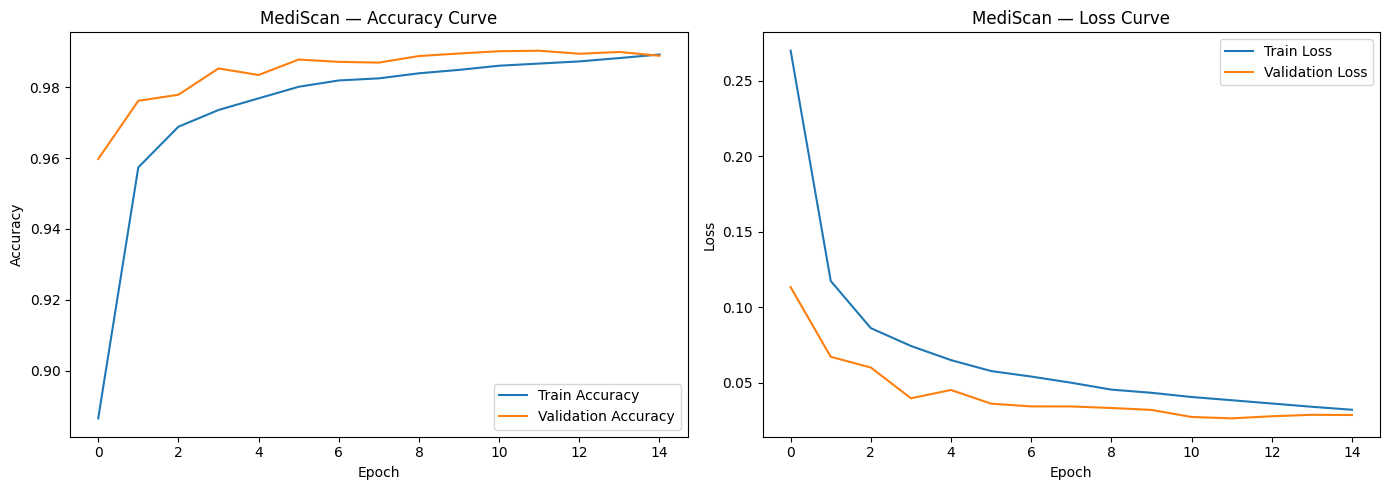

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_q1.history['accuracy'], label='Train Accuracy')
axes[0].plot(history_q1.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('MediScan — Accuracy Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history_q1.history['loss'], label='Train Loss')
axes[1].plot(history_q1.history['val_loss'], label='Validation Loss')
axes[1].set_title('MediScan — Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

### (e) Evaluation

In [8]:
results_q1 = model_q1.evaluate(x_val_q1, y_val_q1, verbose=0)
print(f"Test Accuracy  : {results_q1[1]:.4f}")
print(f"Test Precision : {results_q1[2]:.4f}")
print(f"Test Recall    : {results_q1[3]:.4f}")

Test Accuracy  : 0.9889
Test Precision : 0.9880
Test Recall    : 0.9892


### (e) Discussion — Precision vs. Recall in Healthcare

**In a healthcare context, Recall (Sensitivity) is more critical than Precision.**

Recall measures how many actual Pneumonia cases the model correctly identifies out of all true Pneumonia cases. A high recall means the model misses very few sick patients.

Precision measures how many of the model's Pneumonia predictions are actually correct. Low precision means healthy patients get flagged unnecessarily — causing anxiety and extra tests, but no direct harm.

**Cost of a False Negative (model predicts Normal, patient has Pneumonia):**
- The patient goes home without treatment.
- Pneumonia can progress rapidly, leading to respiratory failure or death.
- The clinical and ethical cost of a missed diagnosis is far higher than a false alarm.
- Therefore, we must maximize Recall even at the expense of some Precision.

### Question 2: FashionAI — Clothing Category Classifier

### (a) Data Loading

In [9]:
(x_train_f, y_train_f), (x_test_f, y_test_f) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

x_train_f = x_train_f / 255.0
x_test_f  = x_test_f  / 255.0

x_train_f = x_train_f.reshape(-1, 28, 28, 1)
x_test_f  = x_test_f.reshape(-1, 28, 28, 1)

print(f"Training samples : {x_train_f.shape[0]}")
print(f"Test samples     : {x_test_f.shape[0]}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples : 60000
Test samples     : 10000


### (b) Exploratory Visualization — 5×5 Sample Grid

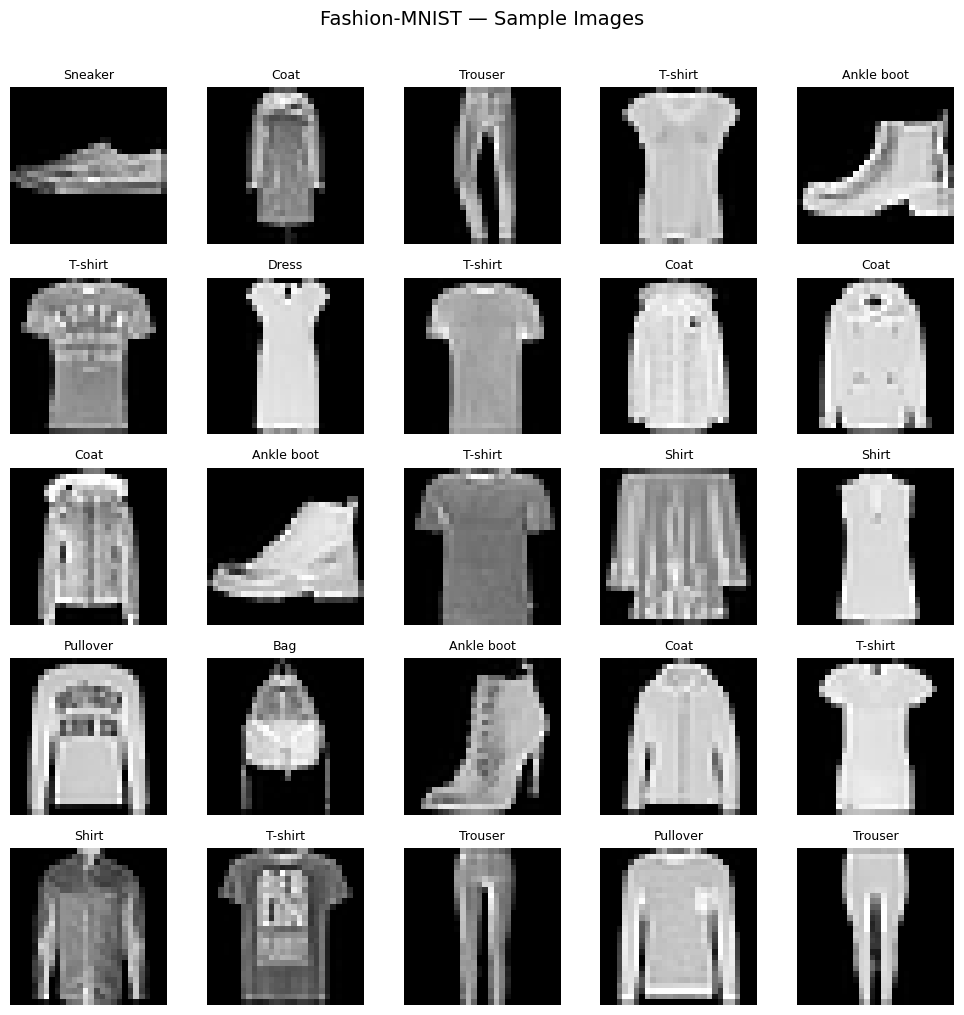

In [10]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))
indices = np.random.choice(len(x_train_f), 25, replace=False)

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_f[indices[i]].reshape(28, 28), cmap='gray')
    ax.set_title(class_names[y_train_f[indices[i]]], fontsize=9)
    ax.axis('off')

plt.suptitle('Fashion-MNIST — Sample Images', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### (c) Model Architecture

In [11]:
model_q2 = models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_q2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,702,026 (6.49 MB)

 Trainable params: 1,701,578 (6.49 MB)

 Non-trainable params: 448 (1.75 KB)

### (d) Training — 20 Epochs

In [12]:
model_q2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_q2 = model_q2.fit(
    x_train_f, y_train_f,
    epochs=20,
    validation_split=0.2,
    batch_size=64
)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8147 - loss: 0.5340 - val_accuracy: 0.8794 - val_loss: 0.3308
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8687 - loss: 0.3650 - val_accuracy: 0.8845 - val_loss: 0.3290
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8848 - loss: 0.3201 - val_accuracy: 0.9069 - val_loss: 0.2638
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8939 - loss: 0.2927 - val_accuracy: 0.8991 - val_loss: 0.2929
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9018 - loss: 0.2749 - val_accuracy: 0.9110 - val_loss: 0.2422
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9070 - loss: 0.2564 - val_accuracy: 0.9160 - val_loss: 0.2363
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9111 - loss: 0.2420 - val_accuracy: 0.9199 - val_loss: 0.2410
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9173 - loss: 0.2269 - val_accuracy: 0

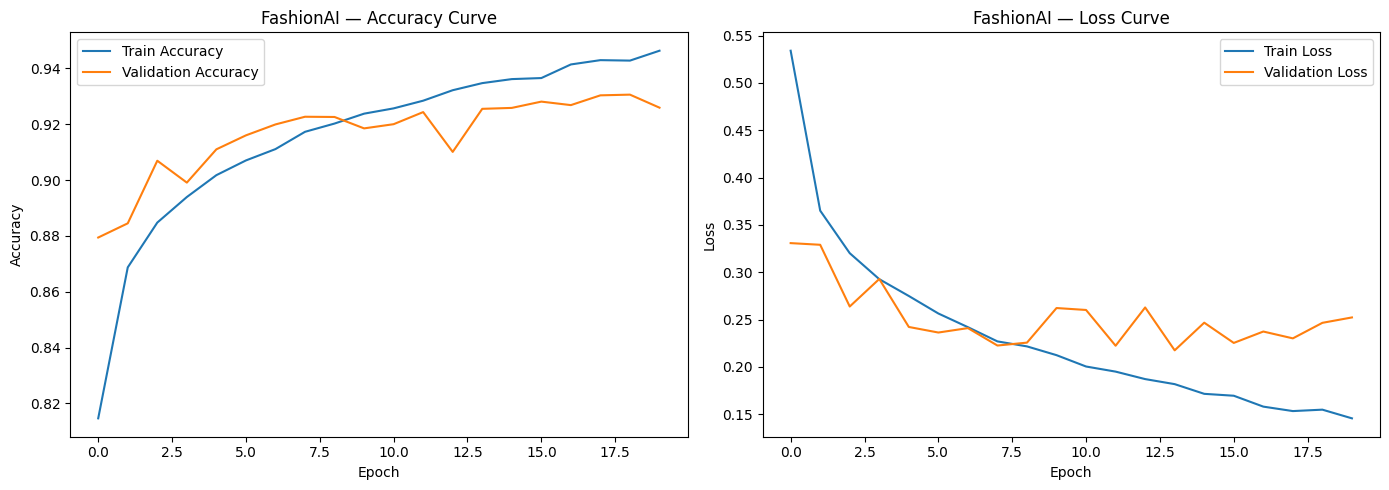

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_q2.history['accuracy'], label='Train Accuracy')
axes[0].plot(history_q2.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('FashionAI — Accuracy Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history_q2.history['loss'], label='Train Loss')
axes[1].plot(history_q2.history['val_loss'], label='Validation Loss')
axes[1].set_title('FashionAI — Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

### (e) Error Analysis — 5 Wrong Predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


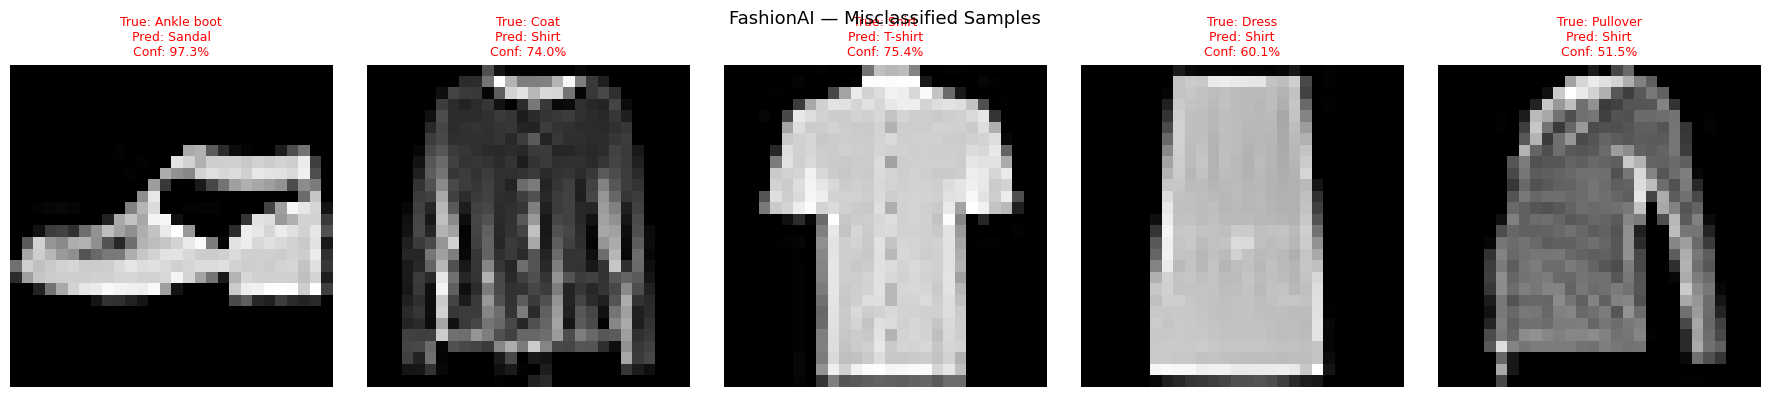

In [14]:
y_pred_probs = model_q2.predict(x_test_f)
y_pred = np.argmax(y_pred_probs, axis=1)

wrong_indices = np.where(y_pred != y_test_f)[0]
selected_wrong = wrong_indices[:5]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, idx in enumerate(selected_wrong):
    confidence = y_pred_probs[idx][y_pred[idx]] * 100
    true_label = class_names[y_test_f[idx]]
    pred_label = class_names[y_pred[idx]]
    axes[i].imshow(x_test_f[idx].reshape(28, 28), cmap='gray')
    axes[i].set_title(
        f"True: {true_label}\nPred: {pred_label}\nConf: {confidence:.1f}%",
        fontsize=9, color='red'
    )
    axes[i].axis('off')

plt.suptitle('FashionAI — Misclassified Samples', fontsize=13)
plt.tight_layout()
plt.show()

In [15]:
test_loss, test_acc = model_q2.evaluate(x_test_f, y_test_f, verbose=0)
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Loss     : {test_loss:.4f}")

Test Accuracy : 0.9233
Test Loss     : 0.2737


### (e) Discussion — Hardest Categories to Distinguish

**The two hardest categories to distinguish are Shirt and T-shirt (or Shirt and Pullover/Coat).**

Visually, these categories share very similar features:
- Both T-shirts and Shirts have a similar boxy torso shape, collar area, and sleeve structure in grayscale.
- At 28×28 pixel resolution, fine details like buttons, collars, and fabric texture — which distinguish a casual shirt from a T-shirt — are largely lost.
- Pullovers and Coats share long sleeves and a closed neckline, making them visually ambiguous in small grayscale images.

The model struggles because these classes occupy nearly identical spatial regions in pixel space, and without color or texture cues, the CNN's filters cannot reliably separate them.